# 08 | Agreement across models at T6 and Brant–delta overlap

Run notebooks 04 through 07 first. These exploratory follow-ups were defined after the initial screen and use the same participants.

**Run in Colab.** See the repository README for Drive access and input paths. Run cells in order and start with notebook 01. Generated files belong in the private working directory. Saved outputs show the original study run.


In [1]:
from pathlib import Path
import os, json, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, rankdata, iqr
from IPython.display import display

if 'EEG_WORK' not in os.environ:
    from google.colab import drive
    drive.mount('/content/drive')
project = Path('/content/drive/MyDrive/پژوهش EEG و میلون — گزارش و نوت‌بوک‌های Colab')
work = Path(os.environ.get('EEG_WORK', project/'ورودی‌های خصوصی بازتحلیل'/'derived'))
cache = Path(os.environ.get('EEG_REFERENCE_DIR', work/'inputs'))
raw_dir = Path(os.environ.get('EEG_RAW', '/content/eeg_mcmi_raw'))
for path in [work,cache,raw_dir]:
    path.mkdir(parents=True,exist_ok=True)
os.chdir(work)
def drive_service():
    from google.colab import auth
    from googleapiclient.discovery import build
    auth.authenticate_user()
    return build('drive','v3',cache_discovery=False)
def read_existing_drive_file(service,file_id,destination):
    from googleapiclient.http import MediaIoBaseDownload
    temp=destination.with_suffix(destination.suffix+'.part')
    with temp.open('wb') as out:
        reader=MediaIoBaseDownload(out,service.files().get_media(fileId=file_id))
        done=False
        while not done:
            _,done=reader.next_chunk()
    temp.replace(destination)
if not (cache/'scores.xlsx').exists():
    original=Path('/content/drive/MyDrive/MCMI_results.xlsx')
    if original.exists():
        shutil.copyfile(original,cache/'scores.xlsx')
    else:
        read_existing_drive_file(drive_service(),'1EOvKbEfvLAQPTjizNE9DEUR9Ik8xBsiy',cache/'scores.xlsx')
scores = pd.read_excel(cache/'scores.xlsx',index_col=0)
assert scores.index.is_unique
manifest=work/'joint/manifest.json'
ids=sorted(s for s in [Path(v[0]).stem for v in json.loads(manifest.read_text())] if scores.loc[s,'سن']>=18) if manifest.exists() else []
channels='Fp1 Fp2 F3 F4 C3 C4 P3 P4 O1 O2 F7 F8 T3 T4 T5 T6 Fz Cz Pz'.split()
def figure(name):
    plt.tight_layout()
    plt.savefig(work/(name+'.png'),dpi=160,bbox_inches='tight')
    plt.show()

Mounted at /content/drive


## What the models agree on at T6

Compute all participant-pair distances for each model and site. Compare EEG distances with anxiety-score distances and with distances from the other models. Evaluate T5 as a comparison site and check sensitivity to a rank-based distance measure.


T6 labram (np.float64(0.16047647674140972), np.float64(0.045797710114494274))
T6 cbramod (np.float64(0.17263400090051095), np.float64(0.036498175091245436))
T6 brant (np.float64(0.1984257357317079), np.float64(0.0343982800859957))
T6 consensus (np.float64(0.22207111417567732), np.float64(0.018449077546122693))
T5 labram (np.float64(0.14946121518608801), np.float64(0.0543972801359932))
T5 cbramod (np.float64(0.11734250341385073), np.float64(0.08254587270636468))
T5 brant (np.float64(0.11174230962884774), np.float64(0.09034548272586371))
T5 consensus (np.float64(0.16567384129079749), np.float64(0.04229788510574471))
two-sided T6-T5 0.232038398080096


site                   T5        T6
model   other                      
cbramod brant    0.197094  0.513519
labram  brant    0.235887  0.484163
        cbramod  0.734737  0.815372

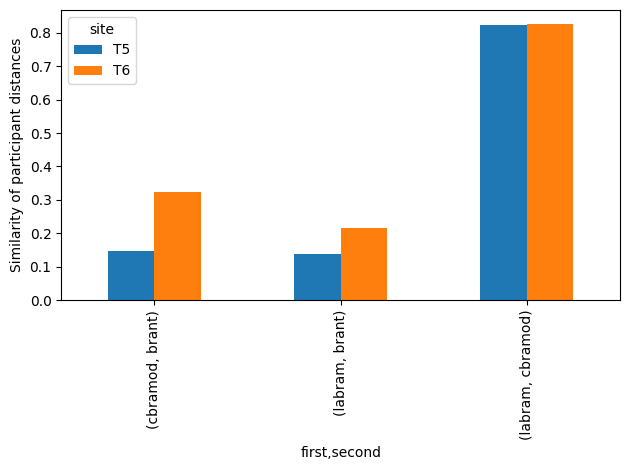

Alternative rank geometry, T6: (np.float64(0.03138986121938973), np.float64(0.3374331283435828))


In [2]:
from scipy.stats import false_discovery_control
def ranked_unit(values):
    ranks=rankdata(values,axis=0)
    ranks-=ranks.mean(axis=0)
    return ranks/np.maximum(np.linalg.norm(ranks,axis=0),1e-20)
def scan(features,outcomes,permutations=20000,seed=23):
    outcomes=outcomes.loc[features.index]
    x=ranked_unit(features.to_numpy()); y=ranked_unit(outcomes.to_numpy())
    observed=x.T@y
    hits=np.ones_like(observed); maxima=[]
    rng=np.random.default_rng(seed)
    for start in range(0,permutations,50):
        order=np.array([rng.permutation(len(x)) for _ in range(min(50,permutations-start))])
        sims=np.abs(x.T@y[order])
        hits+=(sims>=np.abs(observed)-1e-12).sum(0)
        maxima.extend(sims.max(axis=(1,2)))
    p=hits/(permutations+1); q=false_discovery_control(p.ravel()).reshape(p.shape)
    pmax=(1+permutations-np.searchsorted(np.sort(maxima),np.abs(observed)-1e-12))/(permutations+1)
    index=pd.MultiIndex.from_product([features.columns,outcomes.columns],names=['feature','score'])
    return pd.DataFrame(dict(rho=observed.ravel(),p=p.ravel(),q=q.ravel(),pmax=pmax.ravel()),index=index)
def partial(x,y,*controls):
    design=np.column_stack([np.ones(len(x)),*[rankdata(z) for z in controls]])
    ranked=rankdata(np.column_stack([x,y]),axis=0)
    residual=ranked-design@np.linalg.lstsq(design,ranked,rcond=None)[0]
    return np.corrcoef(residual.T)[0,1]

from scipy.spatial.distance import cdist
from sklearn.decomposition import PCA
from itertools import combinations
models={}
for label in ['labram','cbramod','brant']:
    with np.load(work/(label+'_vectors.npz')) as f:
        assert list(f['ids'])==ids and list(f['channels'])==channels
        models[label]=f['vectors']
def distance(x):
    d=cdist(x,x); n=len(d); s=d.sum(0)
    u=d-(s[:,None]+s)/(n-2)+s.sum()/((n-1)*(n-2));np.fill_diagonal(u,0)
    return u/np.linalg.norm(u)
target=distance(rankdata(scores.loc[ids,'BR_A'])[:,None])
rng=np.random.default_rng(42); perms=np.array([rng.permutation(len(ids)) for _ in range(20000)])
def association(matrix):
    value=(matrix*target).sum()
    sim=(matrix*target[perms[:,:,None],perms[:,None,:]]).sum((1,2))
    return value,(1+np.sum(sim>=value-1e-12))/(1+len(sim))
consensus={};similarity={}
for site in ['T6','T5']:
    blocks={m:distance(v[:,channels.index(site)]) for m,v in models.items()}
    for m,mat in blocks.items():print(site,m,association(mat))
    for m,k in combinations(blocks,2):similarity[(site,m,k)]=np.sum(blocks[m]*blocks[k])
    avg=np.mean(list(blocks.values()),axis=0);consensus[site]=avg/np.linalg.norm(avg)
    print(site,'consensus',association(consensus[site]))
difference=consensus['T6']-consensus['T5']
sim=(difference*target[perms[:,:,None],perms[:,None,:]]).sum((1,2))
print('two-sided T6-T5', (1+sum(abs(sim)>=abs((difference*target).sum())-1e-12))/(1+len(sim)))
sim_table=pd.Series(similarity).rename_axis(['site','first','second']).unstack(0)
rank_similarity={}
for site in ['T6','T5']:
    for m,k in combinations(models,2):
        from scipy.spatial.distance import pdist
        i=channels.index(site)
        rank_similarity[site,m,k]=spearmanr(pdist(models[m][:,i]),pdist(models[k][:,i])).statistic
display(pd.Series(rank_similarity).rename_axis(['site','model','other']).unstack(0))
sim_table.to_csv('T6_T5_similarity.csv')
sim_table.plot.bar();plt.ylabel('Similarity of participant distances');figure('08_T6_T5')
from scipy.spatial.distance import pdist,squareform
tri=np.triu_indices(len(ids),1)
def rank_geometry(x):return rankdata(pdist(x))
def rsa_summary(site):
    aa=np.stack([rank_geometry(v[:,channels.index(site)]) for v in models.values()])
    aa=(aa-aa.mean(1,keepdims=True))/aa.std(1,keepdims=True)
    geometry=aa.mean(0)
    score_dist=squareform(rank_geometry(rankdata(scores.loc[ids,'BR_A'])[:,None]))
    value=spearmanr(geometry,score_dist[tri]).statistic
    perm_d=score_dist[perms[:,tri[0]],perms[:,tri[1]]]
    v=ranked_unit(geometry); sampled=(perm_d-perm_d.mean(1,keepdims=True))
    sampled/=np.linalg.norm(sampled,axis=1,keepdims=True)
    return value,(1+sum((sampled@v)>=value))/(len(perms)+1)
print('Alternative rank geometry, T6:',rsa_summary('T6'))

## How much of the F8 association overlaps with delta?

Partial rank correlation removes the contribution of the third ranked variable from the other two. The sign of PC1 depends on the loading orientation.


,BrantF8,DeltaIQR,F8IQR,MeanDelta,BR_8B
BrantF8,1.000000,-0.636842,-0.685965,-0.538596,-0.633527
DeltaIQR,-0.636842,1.000000,0.871930,0.817544,0.700399
F8IQR,-0.685965,0.871930,1.000000,0.663158,0.581613
MeanDelta,-0.538596,0.817544,0.663158,1.000000,0.540258
BR_8B,-0.633527,0.700399,0.581613,0.540258,1.000000


F8 vs 8B | delta -0.3406939405604717
delta vs 8B | F8 0.49777976042530003
F8 vs delta | mean delta -0.40501683870134975
labram F8 vs BR_8B -0.04487482784590757
cbramod F8 vs BR_8B -0.18565860148012742
brant F8 vs BR_8B -0.6335269813539892


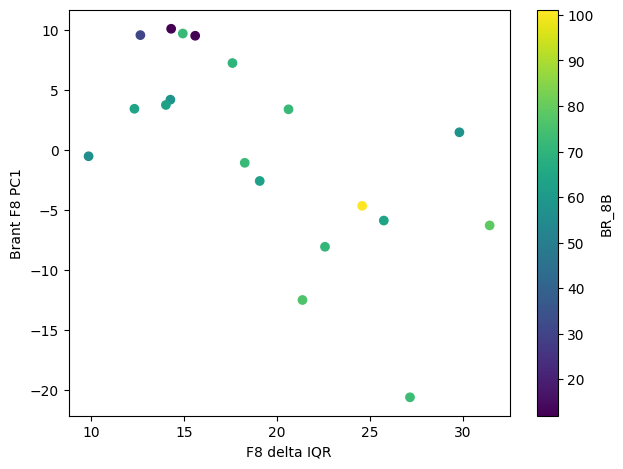

F8 / local delta LOO (np.float64(-0.762641898864809), np.float64(-0.6408668730650156))


In [3]:
a=pd.read_csv('direct_features.csv',index_col=0).loc[ids].join(scores.loc[ids,['BR_8B']])
v=models['brant'][:,channels.index('F8')].astype(float)
p=PCA(1,svd_solver='full').fit(v); a['BrantF8']=p.transform(v)[:,0]
display(a[['BrantF8','DeltaIQR','F8IQR','MeanDelta','BR_8B']].corr(method='spearman'))
print('F8 vs 8B | delta',partial(a.BrantF8,a.BR_8B,a.DeltaIQR))
print('delta vs 8B | F8',partial(a.DeltaIQR,a.BR_8B,a.BrantF8))
print('F8 vs delta | mean delta',partial(a.BrantF8,a.DeltaIQR,a.MeanDelta))
for m,vectors in models.items():
    pc=PCA(1,svd_solver='full').fit_transform(vectors[:,channels.index('F8')].astype(float)).ravel()
    print(m,'F8 vs BR_8B',spearmanr(pc,a.BR_8B).statistic)
plt.scatter(a.F8IQR,a.BrantF8,c=a.BR_8B,cmap='viridis');plt.colorbar(label='BR_8B');plt.xlabel('F8 delta IQR');plt.ylabel('Brant F8 PC1');figure('08_brant_delta')
def loo_f8_delta():
    values=[]
    for i in range(len(ids)):
        mask=np.arange(len(ids))!=i
        fit=PCA(1,svd_solver='full').fit(v[mask])
        pc=fit.transform(v[mask])[:,0]*np.sign(fit.components_[0]@p.components_[0])
        values.append(spearmanr(pc,a.loc[mask,'F8IQR']).statistic)
    return min(values),max(values)
print('F8 / local delta LOO',loo_f8_delta())